# RIKUY_DEEP: deteccion de defectos en piezas de fundicion

Notebook completo y autocontenido, refactorizado conservando el orden de las secciones originales.
Flujo: imágenes originales 512×512 → split persistente → augmentation sólo en train → CNN / MobileNetV2 → evaluación → TensorFlow.js.
**1 = defecto, 0 = ok.** No se importa ni se escribe ningún módulo `ml/`.

**Uso:** ejecuta primero la celda inicial de instalación; ajusta ROOT y STAGES en Configuración. Primera ejecución: download, prepare y cnn/mobilenet según lo que necesites.
El flujo completo está habilitado; las corridas completas se reutilizan. La configuración muestra VERSIÓN ACTIVA: RIKUY_COLAB_ENTRENAMIENTO_V2.
Las corridas completas se reutilizan por huella de datos/configuración/código; las incompletas se conservan y provocan un error antes de repetir entrenamiento.
No se hacen operaciones Git automáticas ni se guardan credenciales en el notebook.

In [1]:
%pip install -q kagglehub dvc dvc-gdrive tensorflowjs mlflow


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-bigquery 3.46.2 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
bigquery-magics 0.14.0 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
db-dtypes 1.9.0 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
langchain-core 1.7.0 requires packaging>=23.2.0, but you have packaging 20.9 which is incompatible.
pandas-gbq 0.30.0 requires packaging>=22.0.0, but you have packaging 20.9 which is incompatible.
libpysal 4.14.1 requires packaging>=23.2, but you hav

## LIBRERIAS

In [2]:
import sys
import hashlib
import importlib.metadata
import json
import math
import random
import shutil
import subprocess
import types
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path
from google.colab import drive
import kagglehub
import matplotlib.pyplot as plt
#import mlflow
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
    confusion_matrix, f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score)

## CONFIGURACIÓN KAGGLE Y GOOGLE DRIVE

In [3]:
# Google Colab: recuperación del modelo guardado, sin reentrenar.
drive.mount("/content/drive", force_remount=False)

ROOT = Path("/content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2")
LOCAL_IMAGE_CACHE = Path("/content/rikuy_image_cache")

REQUIRE_GPU = False
GPU_DEVICES = tf.config.list_physical_devices("GPU")

CLASSES = {"ok_front": 0, "def_front": 1}
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
TARGET_SIZE = (400, 400)


@dataclass(frozen=True)
class Config:
    root: Path
    seed: int = 42
    batch_size: int = 16
    epochs: int = 35
    hpo_epochs: int = 10
    augmentation: bool = True
    target_recall: float = 0.95
    experiment_tag: str = "v1"
    dataset: str = (
        "ravirajsinh45/real-life-industrial-dataset-of-casting-product"
    )

    def __post_init__(self):
        object.__setattr__(self, "root", Path(self.root).resolve())
        if not self.root.is_dir():
            raise FileNotFoundError(f"No existe el repositorio: {self.root}")

    @property
    def raw(self):
        return self.root / "data" / "casting_data"

    @property
    def prepared(self):
        return self.root / "data" / "prepared"


def digest(value):
    return hashlib.sha256(
        json.dumps(value, sort_keys=True).encode()
    ).hexdigest()


def file_hash(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    temporary.replace(path)


def command(config, args, timeout=600):
    result = subprocess.run(
        args,
        cwd=config.root,
        capture_output=True,
        text=True,
        timeout=timeout,
        check=False,
    )
    if result.returncode:
        raise RuntimeError(
            f"Falló el comando:\n{args}\n"
            f"{result.stderr or result.stdout}"
        )
    return result.stdout


def check_artifacts(directory, record):
    directory = Path(directory)
    for name, checksum in record["artifacts"].items():
        path = directory / name
        if not path.is_file():
            raise FileNotFoundError(f"Falta el artefacto: {path}")
        if file_hash(path) != checksum:
            raise ValueError(f"Artefacto incompleto o modificado: {path}")


CONFIG = Config(root=ROOT)

# Sólo se ejecutará la exportación y su registro con DVC.
STAGES = {
    "download": False,
    "dvc_raw": False,
    "prepare": False,
    "eda": False,
    "preview": False,
    "dvc_prepared": False,
    "cnn": False,
    "mobilenet": False,
    "evaluate": False,
    "dvc_models": False,
    "export_tfjs": True,
    "dvc_export": True,
}

PUSH_DVC = False
DVC_REMOTE = "drive"
DVC_REMOTE_URL = ROOT / "dvc_remote"
TRACK_WITH_MLFLOW = False

FINAL_MODEL = "mobilenet"
EXISTING_CNN_RUN = None
EXISTING_MOBILENET_RUN = (
    ROOT
    / "models"
    / "experiments"
    / "mobilenetv2_af731904844ed80545ae"
)

# Se configura posteriormente en la celda del conversor aislado.
TFJS_CONVERTER = None

NOTEBOOK_VERSION = "RIKUY_COLAB_SOLO_EXPORTACION"

# Comprobar que la corrida terminó y sus archivos están intactos.
for name in (
    "best.keras",
    "validation.json",
    "started.json",
    "completed.json",
):
    path = EXISTING_MOBILENET_RUN / name
    if not path.is_file():
        raise FileNotFoundError(
            f"Falta {path}. Comprueba el nombre de la corrida en Drive. "
            "No se iniciará ningún entrenamiento."
        )

check_artifacts(
    EXISTING_MOBILENET_RUN,
    read_json(EXISTING_MOBILENET_RUN / "completed.json"),
)

if not (ROOT / ".dvc").is_dir():
    raise FileNotFoundError(f"No se encontró el repositorio DVC: {ROOT}")

print("VERSIÓN:", NOTEBOOK_VERSION)
print("MODO SÓLO EXPORTACIÓN: sin descarga ni entrenamiento.")
print("Modelo verificado:", EXISTING_MOBILENET_RUN / "best.keras")
print("Validation:", read_json(EXISTING_MOBILENET_RUN / "validation.json"))
print("Remoto DVC:", DVC_REMOTE, "->", DVC_REMOTE_URL)
print("Subir al remoto:", PUSH_DVC)

Mounted at /content/drive
VERSIÓN: RIKUY_COLAB_SOLO_EXPORTACION
MODO SÓLO EXPORTACIÓN: sin descarga ni entrenamiento.
Modelo verificado: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/experiments/mobilenetv2_af731904844ed80545ae/best.keras
Validation: {'threshold': 0.24371959269046783, 'accuracy': 1.0, 'recall': 1.0, 'precision': 1.0, 'f1': 1.0, 'average_precision': 0.9999999999999999, 'roc_auc': 1.0, 'brier': 0.006161490687131598, 'confusion_matrix_0_ok_1_defect': [[78, 0], [0, 117]]}
Remoto DVC: drive -> /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/dvc_remote
Subir al remoto: False


In [58]:
# Google Colab: almacenamiento persistente en Drive.
drive.mount("/content/drive", force_remount=False)
ROOT = Path("/content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2")
ROOT.mkdir(parents=True, exist_ok=True)
LOCAL_IMAGE_CACHE = Path("/content/rikuy_image_cache")
REQUIRE_GPU = True
GPU_DEVICES = tf.config.list_physical_devices("GPU")
print("GPU:", GPU_DEVICES)
print("Repositorio:", ROOT)

CLASSES = {"ok_front": 0, "def_front": 1}
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
TARGET_SIZE = (400, 400)


@dataclass(frozen=True)
class Config:
    root: Path
    seed: int = 42
    batch_size: int = 16
    epochs: int = 35
    hpo_epochs: int = 10
    augmentation: bool = True
    target_recall: float = 0.95
    experiment_tag: str = "v1"
    dataset: str = "ravirajsinh45/real-life-industrial-dataset-of-casting-product"

    def __post_init__(self):
        object.__setattr__(self, "root", Path(self.root).resolve())
        if not self.root.is_dir():
            raise ValueError("ROOT debe ser una carpeta de trabajo existente.")
        if (
            self.batch_size < 1
            or self.epochs < 1
            or self.hpo_epochs < 1
            or (not 0 < self.target_recall <= 1)
        ):
            raise ValueError(
                "batch_size/epochs deben ser positivos; target_recall en (0,1]."
            )

    @property
    def raw(self):
        return self.root / "data" / "casting_data"

    @property
    def prepared(self):
        return self.root / "data" / "prepared"


def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()


def file_hash(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def write_json(path, value):
    """Publicar el marcador sólo cuando está completo; no dejar JSON truncado."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    temporary.replace(path)


def command(config, args, timeout=600):
    """Sin shell, cwd explícito, timeout y errores que detienen el flujo."""
    result = subprocess.run(
        args,
        cwd=config.root,
        capture_output=True,
        text=True,
        timeout=timeout,
        check=False,
    )
    if result.returncode:
        raise RuntimeError(
            f"Falló {args[0]} {args[1]}: {result.stderr or result.stdout}"
        )
    return result.stdout


def check_artifacts(directory, record):
    for name, checksum in record["artifacts"].items():
        if not (directory / name).is_file() or file_hash(directory / name) != checksum:
            raise ValueError(f"Artefacto ausente/modificado: {directory / name}")


CONFIG = Config(
    root=ROOT,
    seed=42,
    batch_size=16,
    epochs=35,
    hpo_epochs=10,
    augmentation=True,
    target_recall=0.95,
    experiment_tag="v1",
)

STAGES = {'download': True,
 'dvc_raw': True,
 'prepare': True,
 'eda': True,
 'preview': True,
 'dvc_prepared': True,
 'cnn': True,
 'mobilenet': True,
 'evaluate': True,
 'dvc_models': True,
 'export_tfjs': True,
 'dvc_export': True}
PUSH_DVC = False
DVC_REMOTE = "drive"  # Debe existir; no se crea/modifica automáticamente.
TRACK_WITH_MLFLOW = False  # Opcional: requiere mlflow instalado en el entorno.
# Selección: "cnn", "mobilenet" o "best_validation". Nunca seleccionar según test.
FINAL_MODEL = "best_validation"
EXISTING_CNN_RUN = (
    None  # ROOT / "models/experiments/cnn_..." para reutilizar otra sesión.
)
EXISTING_MOBILENET_RUN = None
TFJS_CONVERTER = shutil.which("tensorflowjs_converter")
# Si el conversor está en otro entorno, indica su ejecutable absoluto.

# Cada etapa completada registra su resultado con DVC.
STAGES["dvc_raw"] = STAGES["download"]
STAGES["dvc_prepared"] = STAGES["prepare"]
STAGES["dvc_models"] = STAGES["cnn"] or STAGES["mobilenet"] or STAGES["evaluate"]
STAGES["dvc_export"] = STAGES["export_tfjs"]

NOTEBOOK_VERSION = "RIKUY_COLAB_ENTRENAMIENTO_V2"
DVC_REMOTE_URL = ROOT / "dvc_remote"
print("VERSIÓN ACTIVA:", NOTEBOOK_VERSION)
print("CNN:", STAGES["cnn"], "| MobileNetV2:", STAGES["mobilenet"])
print("DVC:", DVC_REMOTE, "->", DVC_REMOTE_URL)
if not (ROOT / ".dvc").is_dir():
    raise FileNotFoundError(f"ROOT debe ser el repositorio DVC: {ROOT}")
if REQUIRE_GPU and (STAGES["cnn"] or STAGES["mobilenet"]) and not GPU_DEVICES:
    raise RuntimeError("Activa GPU en Colab antes de continuar.")
DVC_REMOTE_URL.mkdir(parents=True, exist_ok=True)
remotes = {}
for line in command(CONFIG, ["dvc", "remote", "list"]).splitlines():
    fields = line.strip().split(maxsplit=1)
    if len(fields) == 2 and fields[0] == DVC_REMOTE:
        remotes[fields[0]] = fields[1].strip()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Repositorio: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2
VERSIÓN ACTIVA: RIKUY_COLAB_ENTRENAMIENTO_V2
CNN: True | MobileNetV2: True
DVC: drive -> /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/dvc_remote


## Descargando el dataset

In [59]:
def validate_raw_layout(directory):
    for class_name in CLASSES:
        paths = list((directory / class_name).glob("*"))
        if not any(p.is_file() and p.suffix.lower() in EXTENSIONS for p in paths):
            raise ValueError(f"Clase vacía o ausente: {directory / class_name}")
    return directory


def download_dataset(config):
    """Una sola copia canónica; nunca mezclar una descarga con datos parciales."""
    if config.raw.exists():
        validate_raw_layout(config.raw)
        return config.raw
    downloaded = Path(kagglehub.dataset_download(config.dataset))
    candidates = [
        downloaded,
        downloaded / "casting_512x512",
        downloaded / "casting_512x512" / "casting_512x512",
    ]
    source = next(
        (p for p in candidates if all(((p / c).is_dir() for c in CLASSES))), None
    )
    if source is None:
        raise FileNotFoundError(
            f"No se encontraron las clases 512x512 en {downloaded}."
        )
    pending = config.raw.with_name("casting_data.pending")
    if pending.exists():
        raise RuntimeError(
            f"Descarga interrumpida: revisa {pending} antes de reintentar."
        )
    pending.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(source, pending)
    pending.rename(config.raw)
    validate_raw_layout(config.raw)
    return config.raw


if STAGES["download"]:
    print(download_dataset(CONFIG))


/content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/data/casting_data


## Versionando el dataset

In [4]:
def version_with_dvc(config, target, push=False, remote=None, timeout=3600):
    """Un único add incremental; comparar el puntero para informar cambios reales."""
    target = Path(target).resolve()
    root = config.root.resolve()
    relative = target.relative_to(root)
    if target == root or not target.exists() or not (root / ".dvc").is_dir() or not shutil.which("dvc"):
        raise ValueError("DVC o target no disponibles; el target debe estar dentro del repositorio.")
    for parent in target.parents:
        if parent == root:
            break
        if Path(str(parent) + ".dvc").exists():
            raise ValueError(f"Output DVC anidado bajo {parent}; versiona el padre.")
    if push:
        if not remote:
            raise ValueError("Indica remote antes de publicar.")
        lines = command(config, ["dvc", "remote", "list"]).splitlines()
        if not any(len(fields := line.split(maxsplit=1)) == 2 and fields[0] == remote for line in lines):
            raise ValueError(f"Remoto DVC no configurado: {remote}")
    pointer_path = Path(str(target) + ".dvc")
    pointer = pointer_path.relative_to(root).as_posix()
    before = file_hash(pointer_path) if pointer_path.is_file() else None
    print(f"DVC: registrando {relative.as_posix()} (límite {timeout}s; Drive puede tardar)...", flush=True)
    try:
        # add ya detecta cambios y reutiliza contenido: no precederlo con otro escaneo status.
        output = command(config, ["dvc", "add", relative.as_posix()], timeout=timeout)
        if output.strip():
            print(output)
        if not pointer_path.is_file():
            raise RuntimeError(f"DVC no generó el puntero esperado: {pointer}")
        changed = before != file_hash(pointer_path)
        print("DVC:", "puntero actualizado" if changed else "sin cambios en el puntero", pointer, flush=True)
        if push:
            # push es incremental y reintenta subidas pendientes aunque el puntero no cambie.
            print(f"DVC: sincronizando {pointer} con {remote}...", flush=True)
            output = command(config, ["dvc", "push", pointer, "--remote", remote], timeout=timeout)
            if output.strip():
                print(output)
    except subprocess.TimeoutExpired as exc:
        raise RuntimeError(
            f"DVC superó {timeout}s en {exc.cmd}. No se continúa ni se declara la etapa completa. "
            "Revisa acceso a Drive y espacio disponible antes de reintentar."
        ) from exc
    return {"pointer": pointer, "updated": changed, "push_requested": push}

if STAGES["dvc_raw"]:
    print(version_with_dvc(CONFIG, ROOT / "data", push=PUSH_DVC, remote=DVC_REMOTE))


## Preprocesamiento de imagenes | Data augmentation

In [ ]:
def inventory(config):
    """Validación completa y huella por contenido RGB; detecta duplicados recodificados."""
    rows, seen = ([], {})
    for class_name, label in CLASSES.items():
        paths = sorted((p for p in (config.raw / class_name).rglob('*') if p.suffix.lower() in EXTENSIONS))
        if not paths:
            raise ValueError(f'Clase vacía o ausente: {class_name}')
        for path in paths:
            with Image.open(path) as image:
                image = image.convert('RGB')
                image.load()
                pixel_hash = hashlib.sha256(str(image.size).encode() + image.tobytes()).hexdigest()
                width, height = image.size
            if pixel_hash in seen and seen[pixel_hash] != label:
                raise ValueError(f'La misma imagen tiene etiquetas contradictorias: {path}')
            seen[pixel_hash] = label
            rows.append({'path': path.relative_to(config.root).as_posix(), 'label': label, 'class_name': class_name, 'sha256': file_hash(path), 'pixel_hash': pixel_hash, 'width': width, 'height': height})
    return rows

def prepare_data(config):
    """Split fijo 70/15/15 por imagen RGB única; no generar copias JPEG procesadas."""
    rows = inventory(config)
    identity = digest({'rows': rows, 'seed': config.seed, 'split_algorithm': 1})
    path = config.prepared / 'manifest.json'
    if path.exists():
        old = read_json(path)
        if old['identity'] == identity:
            validate_manifest(config, old)
            return old
        raise RuntimeError('Los datos/semilla cambiaron. Conserva el manifiesto anterior con DVC y retira data/prepared explícitamente antes de crear otro split.')
    unique = {row['pixel_hash']: row.copy() for row in rows}
    result = []
    rng = random.Random(config.seed)
    for label in CLASSES.values():
        group = sorted((r for r in unique.values() if r['label'] == label), key=lambda r: r['path'])
        if len(group) < 7:
            raise ValueError('Se requieren al menos 7 imágenes únicas por clase para 70/15/15.')
        rng.shuffle(group)
        n_test = n_val = max(1, round(len(group) * 0.15))
        for i, row in enumerate(group):
            row['split'] = 'test' if i < n_test else 'validation' if i < n_test + n_val else 'train'
            result.append(row)
    manifest = {'identity': identity, 'seed': config.seed, 'source_rows': rows, 'rows_digest': digest(result), 'duplicates_removed': len(rows) - len(unique), 'rows': result}
    validate_manifest(config, manifest)
    write_json(path, manifest)
    return manifest

def validate_manifest(config, manifest):
    """Fallar antes de entrenar si cambió el inventario, el contenido o el split."""
    current = inventory(config)
    if manifest.get('rows_digest') != digest(manifest['rows']):
        raise ValueError('El contenido del manifiesto fue modificado.')
    expected = digest({'rows': current, 'seed': config.seed, 'split_algorithm': 1})
    if manifest['identity'] != expected or current != manifest['source_rows']:
        raise ValueError('El dataset ya no coincide con el manifiesto. No se entrenará con datos mezclados.')
    hashes = set()
    source = {r['pixel_hash']: r for r in current}
    for row in manifest['rows']:
        original = source.get(row['pixel_hash'])
        if original is None or any((row[k] != original[k] for k in original)):
            raise ValueError('Fila del manifiesto no coincide con la fuente.')
        if row['pixel_hash'] in hashes or row['split'] not in {'train', 'validation', 'test'}:
            raise ValueError('Duplicados o partición inválida en manifiesto.')
        hashes.add(row['pixel_hash'])
    if hashes != set(source):
        raise ValueError('El manifiesto omite imágenes únicas.')
    for split in ('train', 'validation', 'test'):
        if {r['label'] for r in manifest['rows'] if r['split'] == split} != {0, 1}:
            raise ValueError(f'{split} debe contener ambas clases.')

def load_manifest(config):
    path = config.prepared / 'manifest.json'
    if not path.is_file():
        raise FileNotFoundError('Ejecuta prepare_data antes de esta etapa.')
    manifest = read_json(path)
    validate_manifest(config, manifest)
    return manifest

def preprocess_image(image):
    """Acepta ruta, PIL.Image o ndarray RGB; retorna float32 (400,400,3) en [0,1]."""
    if isinstance(image, (str, Path)):
        with Image.open(image) as source:
            image = source.convert('RGB')
    elif isinstance(image, np.ndarray):
        image = Image.fromarray(np.asarray(image, dtype=np.uint8))
    image = image.convert('RGB').resize(TARGET_SIZE, Image.Resampling.BILINEAR)
    return np.asarray(image, dtype=np.float32) / 255.0

def make_tf_dataset(paths, labels, training=False, batch_size=32, seed=42, augment=None):
    """Shuffle sólo en train; augment=None conserva compatibilidad con training."""
    paths = [str(p) for p in paths]
    labels = np.asarray(labels, dtype=np.int32)
    augment = training if augment is None else augment
    if augment and (not training):
        raise ValueError('Augmentation sólo está permitida en train.')
    if not paths or len(paths) != len(labels) or batch_size < 1:
        raise ValueError('Paths/labels deben ser no vacíos, iguales en longitud; batch_size positivo.')
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=seed, reshuffle_each_iteration=True)
    rotation = tf.keras.layers.RandomRotation(0.04, fill_mode='reflect', seed=seed)

    def decode(path, label):
        image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, TARGET_SIZE, method='bilinear')
        image = tf.cast(image, tf.float32) / 255.0
        if augment:
            image = tf.image.random_flip_left_right(image, seed=seed)
            image = rotation(image, training=True)
            image = tf.image.random_brightness(image, max_delta=0.15, seed=seed)
            image = tf.clip_by_value(image, 0.0, 1.0)
        return (image, label)
    return ds.map(decode, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size).prefetch(tf.data.AUTOTUNE)

def cache_training_images(config, manifest):
    """Una copia local por versión: evita leer imágenes de Drive en cada época."""
    directory = LOCAL_IMAGE_CACHE / manifest['identity']
    directory.mkdir(parents=True, exist_ok=True)
    paths, pending = ({}, [])
    for row in manifest['rows']:
        target = (directory / row['path']).resolve()
        if not target.is_relative_to(directory.resolve()):
            raise ValueError('Ruta fuera de la caché local.')
        paths[row['path']] = target
        if not target.is_file() or file_hash(target) != row['sha256']:
            pending.append((row, target))
    required = sum(((config.root / row['path']).stat().st_size for row, _ in pending))
    if required > shutil.disk_usage(directory).free:
        raise RuntimeError('No hay espacio suficiente para la caché local de Colab.')
    for row, target in pending:
        target.parent.mkdir(parents=True, exist_ok=True)
        temporary = target.with_name(target.name + '.partial')
        shutil.copyfile(config.root / row['path'], temporary)
        if file_hash(temporary) != row['sha256']:
            raise ValueError('La imagen cambió durante la copia a la caché.')
        temporary.replace(target)
    return paths

def datasets(config, manifest, augmentation=False):
    local_paths = cache_training_images(config, manifest)
    output = {}
    for split in ('train', 'validation', 'test'):
        rows = [r for r in manifest['rows'] if r['split'] == split]
        output[split] = make_tf_dataset([local_paths[r['path']] for r in rows], [r['label'] for r in rows], training=split == 'train', augment=augmentation and split == 'train', batch_size=config.batch_size, seed=config.seed)
    return output

def show_eda(config, manifest=None):
    if manifest is None:
        manifest = load_manifest(config)
    frame = pd.DataFrame(manifest['rows'])
    print(frame.groupby(['split', 'class_name']).size().unstack(fill_value=0))
    print(frame.groupby('class_name')[['width', 'height']].agg(['min', 'median', 'max']))
    print('Duplicados RGB excluidos:', manifest['duplicates_removed'])
    frame.groupby(['split', 'class_name']).size().unstack().plot.bar(title='Particiones sin duplicados RGB')
    plt.tight_layout()
    plt.show()
    return frame

def preview_augmentation(config, manifest=None):
    if manifest is None:
        manifest = load_manifest(config)
    row = next((row for row in manifest['rows'] if row['split'] == 'train'))
    sample = config.root / row['path']
    augmented, _ = next(iter(make_tf_dataset([sample], [row['label']], training=True, augment=True, batch_size=1, seed=config.seed)))
    original, _ = next(iter(make_tf_dataset([sample], [row['label']], training=False, augment=False, batch_size=1, seed=config.seed)))
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    for ax, pixels, title in zip(axes, [original[0], augmented[0]], ['Train original', 'Train augmentado']):
        ax.imshow(pixels.numpy())
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()


In [22]:
# Compartir el manifiesto validado entre las etapas de esta celda.
manifest = None
if STAGES["prepare"]:
    print("PREPARACIÓN: validando datos y creando/reutilizando el split...")
    manifest = prepare_data(CONFIG)
elif any(STAGES[name] for name in ("eda", "preview", "dvc_prepared")):
    print("CARGA: recuperando y validando el manifiesto existente...")
    manifest = load_manifest(CONFIG)

if manifest is not None:
    print("Imágenes únicas:", len(manifest["rows"]),
          "| Duplicados excluidos:", manifest["duplicates_removed"])
    print("Datos originales:", CONFIG.raw)
    print("Manifiesto:", CONFIG.prepared / "manifest.json")
if STAGES["eda"]:
    eda = show_eda(CONFIG, manifest=manifest)
if STAGES["preview"]:
    preview_augmentation(CONFIG, manifest=manifest)
if STAGES["dvc_prepared"]:
    print("VERSIONADO: datos originales y manifiesto de particiones")
    print(version_with_dvc(CONFIG, ROOT / "data", push=PUSH_DVC, remote=DVC_REMOTE))
if manifest is None:
    print("Preparación, EDA, preview y versionado omitidos por configuración.")


Preparación, EDA, preview y versionado omitidos por configuración.


## Entrenando el dataset con un CNN

In [ ]:
def runtime_versions():
    return {
        name: importlib.metadata.version(name)
        for name in ("tensorflow", "numpy", "scikit-learn", "pillow")
    }


def choose_threshold(y, probabilities, target_recall):
    precision, recall, thresholds = precision_recall_curve(y, probabilities)
    valid = np.flatnonzero(recall[:-1] >= target_recall)
    index = int(valid[np.argmax(precision[valid])])
    return float(thresholds[index])


def scores(y, probabilities, threshold):
    prediction = (np.asarray(probabilities) >= threshold).astype(int)
    return {
        "accuracy": float(accuracy_score(y, prediction)),
        "recall": float(recall_score(y, prediction)),
        "precision": float(precision_score(y, prediction, zero_division=0)),
        "f1": float(f1_score(y, prediction)),
        "average_precision": float(average_precision_score(y, probabilities)),
        "roc_auc": float(roc_auc_score(y, probabilities)),
        "brier": float(brier_score_loss(y, probabilities)),
        "confusion_matrix_0_ok_1_defect": confusion_matrix(
            y, prediction, labels=[0, 1]
        ).tolist(),
    }


def select_model(config, directories):
    """Comparar candidatos sin consultar test."""

    def rank(directory):
        value = read_json(Path(directory) / "validation.json")
        return (
            value["recall"] >= config.target_recall,
            value["accuracy"],
            value["average_precision"],
        )

    if not directories:
        raise ValueError(
            "No hay candidatos. Entrena uno o indica una corrida existente."
        )
    return max(map(Path, directories), key=rank)


def evaluate(config, directory):
    """Evaluación explícita, posterior a selección; reutiliza reporte verificado."""
    directory = Path(directory)
    manifest = load_manifest(config)
    record = read_json(directory / "completed.json")
    check_artifacts(directory, record)
    started = read_json(directory / "started.json")
    if started["manifest"] != manifest:
        raise ValueError("El split del modelo no coincide con el dataset actual.")
    report = directory / "test.json"
    if report.exists():
        cached = read_json(report)
        if cached["run_identity"] != record["identity"]:
            raise ValueError("Reporte test no corresponde al modelo.")
        return cached
    model = tf.keras.models.load_model(directory / "best.keras")
    probabilities = model.predict(datasets(config, manifest)["test"], verbose=0).ravel()
    y = [r["label"] for r in manifest["rows"] if r["split"] == "test"]
    threshold = read_json(directory / "validation.json")["threshold"]
    metrics = {
        "run_identity": record["identity"],
        "threshold_from_validation": threshold,
        **scores(y, probabilities, threshold),
    }
    write_json(report, metrics)
    return metrics


def build_cnn(dropout):
    inputs = tf.keras.Input((*TARGET_SIZE, 3))
    x = inputs
    for filters in (32, 64, 128, 128):
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)
        x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(
        tf.keras.layers.Dropout(dropout)(x)
    )
    return tf.keras.Model(inputs, outputs, name="cnn_casting")


def build_model(kind, learning_rate, dropout, fraction):
    if kind == "cnn":
        model = build_cnn(dropout)
    elif kind == "mobilenetv2":
        model = build_mobilenet(dropout, fraction)
    else:
        raise ValueError(f"Arquitectura desconocida: {kind}")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc_pr", curve="PR"),
        ],
    )
    return model


def notebook_code_fingerprint(kind):
    """Huella del código ejecutado, independiente de rutas y número de celda."""

    def normalize(value):
        if isinstance(value, types.CodeType):
            return {
                "bytecode": value.co_code.hex(),
                "constants": normalize(value.co_consts),
                "names": value.co_names,
                "variables": value.co_varnames,
                "freevars": value.co_freevars,
                "cellvars": value.co_cellvars,
                "argcount": value.co_argcount,
                "kwonly": value.co_kwonlyargcount,
                "posonly": value.co_posonlyargcount,
                "flags": value.co_flags,
                "exceptions": getattr(value, "co_exceptiontable", b"").hex(),
            }
        if isinstance(value, (set, frozenset)):
            return sorted((normalize(item) for item in value), key=repr)
        if isinstance(value, (tuple, list)):
            return [normalize(item) for item in value]
        if value is None or isinstance(value, (str, int, float, bool)):
            return value
        return repr(value)

    functions = {
        name: normalize(globals()[name].__code__)
        for name in TRAINING_FUNCTION_NAMES
        + (["build_mobilenet"] if kind == "mobilenetv2" else [])
    }
    functions["Config.__post_init__"] = normalize(Config.__post_init__.__code__)
    functions["constants"] = {
        "classes": CLASSES,
        "extensions": sorted(EXTENSIONS),
        "target_size": TARGET_SIZE,
    }
    return digest(functions)


def train(
    config,
    kind="cnn",
    augmentation=None,
    learning_rate=0.001,
    dropout=0.35,
    fraction=0.15,
):
    """Reutilizar corrida completa por huella; una corrida interrumpida exige un nuevo tag."""
    if (
        kind not in {"cnn", "mobilenetv2"}
        or learning_rate <= 0
        or (not 0 <= dropout < 1)
        or (not 0 <= fraction <= 1)
    ):
        raise ValueError("Hiperparámetros inválidos.")
    manifest = load_manifest(config)
    augmentation = config.augmentation if augmentation is None else augmentation
    params = {
        **asdict(config),
        "root": None,
        "kind": kind,
        "augmentation": augmentation,
        "learning_rate": learning_rate,
        "dropout": dropout,
        "fraction": fraction,
    }
    code = {"notebook_functions": notebook_code_fingerprint(kind)}
    identity = digest(
        {
            "params": params,
            "manifest": manifest,
            "code": code,
            "versions": runtime_versions(),
        }
    )
    directory = config.root / "models" / "experiments" / f"{kind}_{identity[:20]}"
    completed = directory / "completed.json"
    if completed.exists():
        record = read_json(completed)
        check_artifacts(directory, record)
        return directory
    directory.parent.mkdir(parents=True, exist_ok=True)
    if directory.exists():
        raise RuntimeError(
            f"Corrida incompleta: {directory}. Cambia experiment_tag para reintentar sin sobreescribirla."
        )
    directory.mkdir(exist_ok=False)
    environment = sorted(
        (
            f"{d.metadata['Name']}=={d.version}"
            for d in importlib.metadata.distributions()
        )
    )
    write_json(
        directory / "started.json",
        {
            "identity": identity,
            "params": params,
            "versions": runtime_versions(),
            "environment": environment,
            "created_utc": datetime.now(timezone.utc).isoformat(),
            "code": code,
            "manifest": manifest,
        },
    )
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(config.seed)
    tf.config.experimental.enable_op_determinism()
    ds = datasets(config, manifest, augmentation)
    labels = [r["label"] for r in manifest["rows"] if r["split"] == "train"]
    class_weight = {label: len(labels) / (2 * labels.count(label)) for label in (0, 1)}
    model = build_model(kind, learning_rate, dropout, fraction)
    model.fit(
        ds["train"],
        validation_data=ds["validation"],
        epochs=config.hpo_epochs if kind == "mobilenetv2" else config.epochs,
        class_weight=class_weight,
        callbacks=[
            tf.keras.callbacks.ModelCheckpoint(
                str(directory / "best.keras"),
                monitor="val_auc_pr",
                mode="max",
                save_best_only=True,
            ),
            tf.keras.callbacks.EarlyStopping(
                monitor="val_auc_pr", mode="max", patience=4
            ),
            tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_auc_pr", mode="max", patience=2
            ),
            tf.keras.callbacks.CSVLogger(str(directory / "history.csv")),
        ],
        verbose=2,
    )
    model = tf.keras.models.load_model(directory / "best.keras")
    probabilities = model.predict(ds["validation"], verbose=0).ravel()
    y = [r["label"] for r in manifest["rows"] if r["split"] == "validation"]
    threshold = choose_threshold(y, probabilities, config.target_recall)
    write_json(
        directory / "validation.json",
        {"threshold": threshold, **scores(y, probabilities, threshold)},
    )
    write_json(
        completed,
        {
            "identity": identity,
            "artifacts": {
                name: file_hash(directory / name)
                for name in (
                    "best.keras",
                    "history.csv",
                    "validation.json",
                    "started.json",
                )
            },
        },
    )
    return directory


def plot_history(directory):
    frame = pd.read_csv(Path(directory) / "history.csv")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, metric in zip(axes, ["loss", "accuracy", "auc_pr"]):
        ax.plot(frame[metric], label="train")
        ax.plot(frame["val_" + metric], label="validation")
        ax.set(title=metric, xlabel="Época")
        ax.legend()
    plt.tight_layout()
    plt.show()


def log_experiment(config, directory):
    """Registro opcional en un experimento estable; no copiar otra vez el modelo pesado."""
    if not TRACK_WITH_MLFLOW:
        return
    record = read_json(Path(directory) / "completed.json")
    check_artifacts(Path(directory), record)
    started = read_json(Path(directory) / "started.json")
    tracking = config.root / "mlruns"
    tracking.mkdir(parents=True, exist_ok=True)
    mlflow.set_tracking_uri("sqlite:///" + (tracking / "tracking.db").as_posix())
    experiment = mlflow.get_experiment_by_name("RIKUY_CASTING")
    if experiment is None:
        mlflow.create_experiment(
            "RIKUY_CASTING", artifact_location=(tracking / "artifacts").as_uri()
        )
    experiment = mlflow.get_experiment_by_name("RIKUY_CASTING")
    existing = mlflow.search_runs(
        experiment_ids=[experiment.experiment_id],
        filter_string=f"tags.run_identity = '{record['identity']}'",
        max_results=1,
    )
    if not existing.empty:
        return
    with mlflow.start_run(
        experiment_id=experiment.experiment_id, run_name=Path(directory).name
    ):
        mlflow.set_tags(
            {
                "run_identity": record["identity"],
                "dataset_identity": started["manifest"]["identity"],
            }
        )
        mlflow.log_params({k: str(v) for k, v in started["params"].items()})
        mlflow.log_param("dvc_artifact_path", str(directory))
        values = read_json(Path(directory) / "validation.json")
        mlflow.log_metrics(
            {
                "validation_" + k: v
                for k, v in values.items()
                if isinstance(v, (int, float))
            }
        )
        for name in (
            "started.json",
            "completed.json",
            "history.csv",
            "validation.json",
        ):
            mlflow.log_artifact(str(Path(directory) / name))


TRAINING_FUNCTION_NAMES = [
    "digest",
    "file_hash",
    "read_json",
    "write_json",
    "check_artifacts",
    "inventory",
    "validate_manifest",
    "load_manifest",
    "cache_training_images",
    "preprocess_image",
    "make_tf_dataset",
    "datasets",
    "runtime_versions",
    "choose_threshold",
    "scores",
    "build_cnn",
    "build_model",
    "train",
]


INICIANDO CNN: se entrenará o recuperará un checkpoint completo
Epoch 1/35
57/57 - 36s - 638ms/step - accuracy: 0.6692 - auc_pr: 0.7907 - loss: 0.6211 - val_accuracy: 0.4000 - val_auc_pr: 0.8381 - val_loss: 1.0215 - learning_rate: 0.0010
Epoch 2/35
57/57 - 29s - 501ms/step - accuracy: 0.7143 - auc_pr: 0.8403 - loss: 0.5525 - val_accuracy: 0.4000 - val_auc_pr: 0.8752 - val_loss: 1.0925 - learning_rate: 0.0010
Epoch 3/35
57/57 - 29s - 503ms/step - accuracy: 0.7231 - auc_pr: 0.8523 - loss: 0.5461 - val_accuracy: 0.4000 - val_auc_pr: 0.8936 - val_loss: 1.1191 - learning_rate: 0.0010
Epoch 4/35
57/57 - 29s - 508ms/step - accuracy: 0.7429 - auc_pr: 0.8747 - loss: 0.5099 - val_accuracy: 0.4000 - val_auc_pr: 0.8958 - val_loss: 1.0640 - learning_rate: 0.0010
Epoch 5/35
57/57 - 30s - 519ms/step - accuracy: 0.7615 - auc_pr: 0.8739 - loss: 0.5122 - val_accuracy: 0.4000 - val_auc_pr: 0.9077 - val_loss: 0.9956 - learning_rate: 0.0010
Epoch 6/35
57/57 - 28s - 498ms/step - accuracy: 0.7549 - auc_pr: 0

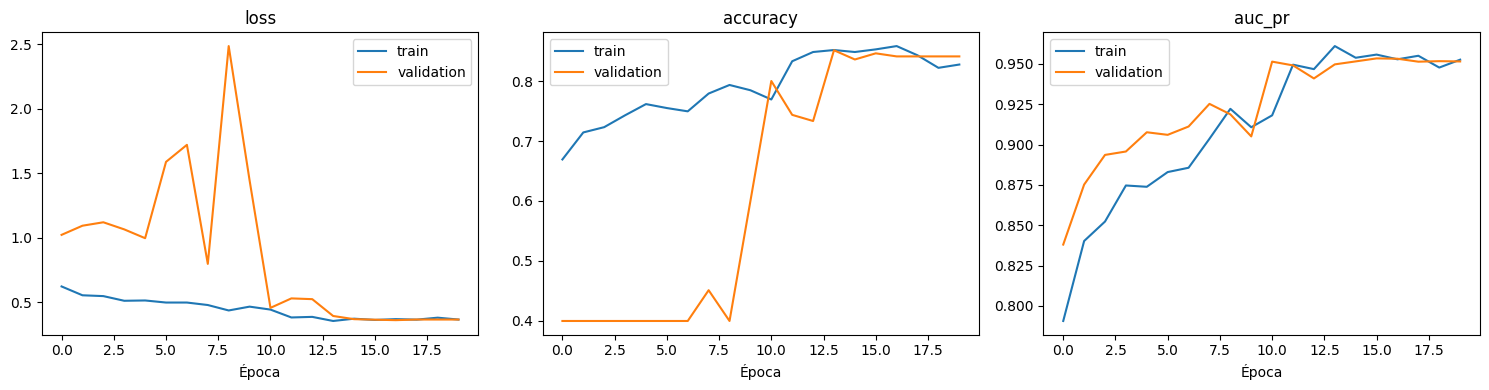

DVC: registrando models/experiments/cnn_0886feef8481deebae90 (límite 3600s; Drive puede tardar)...

To track the changes with git, run:

	git add models/experiments/.gitignore models/experiments/cnn_0886feef8481deebae90.dvc

To enable auto staging, run:

	dvc config core.autostage true

DVC: puntero actualizado models/experiments/cnn_0886feef8481deebae90.dvc
{'pointer': 'models/experiments/cnn_0886feef8481deebae90.dvc', 'updated': True, 'push_requested': False}


In [ ]:
cnn_run = Path(EXISTING_CNN_RUN) if EXISTING_CNN_RUN else None
if STAGES["cnn"]:
    print("INICIANDO CNN: se entrenará o recuperará un checkpoint completo")
    cnn_run = train(CONFIG, kind="cnn", augmentation=CONFIG.augmentation)
    log_experiment(CONFIG, cnn_run)
    print("CNN:", cnn_run)
    print("Validation:", read_json(cnn_run / "validation.json"))
    plot_history(cnn_run)

if STAGES["cnn"] and cnn_run is not None:
    print(version_with_dvc(CONFIG, cnn_run, push=PUSH_DVC, remote=DVC_REMOTE))


## Aplicando Transfer learning (MobileNetV2)

In [ ]:
def build_mobilenet(dropout, fraction):
    inputs = tf.keras.Input((*TARGET_SIZE, 3))
    base = tf.keras.applications.MobileNetV2(
        include_top=False, weights="imagenet", input_shape=(*TARGET_SIZE, 3)
    )
    base.trainable = True
    cutoff = len(base.layers) - math.ceil(len(base.layers) * fraction)
    for i, layer in enumerate(base.layers):
        layer.trainable = i >= cutoff and not isinstance(
            layer, tf.keras.layers.BatchNormalization
        )
    # El pipeline entrega [0,1]; MobileNetV2 necesita [-1,1]. Se integra dentro del modelo.
    x = base(tf.keras.layers.Rescaling(2.0, offset=-1.0)(inputs), training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    return tf.keras.Model(inputs, outputs, name="mobilenetv2_casting")


def run_hpo(config):
    """Sólo validation selecciona el candidato. Cada corrida se puede reutilizar."""
    trials = [
        (0.0001, 0.15, 0.3),
        (5e-05, 0.25, 0.4),
        (2e-05, 0.35, 0.3),
        (1e-05, 0.5, 0.5),
    ]
    directories = [
        train(
            config, "mobilenetv2", learning_rate=lr, fraction=fraction, dropout=dropout
        )
        for lr, fraction, dropout in trials
    ]
    for directory in directories:
        log_experiment(config, directory)
    return select_model(config, directories)


INICIANDO MobileNetV2: cuatro configuraciones de entrenamiento


/tmp/ipykernel_1194/3766621466.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
57/57 - 32s - 554ms/step - accuracy: 0.7923 - auc_pr: 0.9249 - loss: 0.4194 - val_accuracy: 0.8564 - val_auc_pr: 0.9988 - val_loss: 0.2598 - learning_rate: 1.0000e-04
Epoch 2/10
57/57 - 23s - 408ms/step - accuracy: 0.8901 - auc_pr: 0.9730 - loss: 0.2668 - val_accuracy: 0.9692 - val_auc_pr: 0.9990 - val_loss: 0.1040 - learning_rate: 1.0000e-04
Epoch 3/10
57/57 - 24s - 425ms/step - accuracy: 0.9681 - auc_pr: 0.9981 - loss: 0.0857 - val_accuracy: 0.9846 - val_auc_pr: 0.9999 - val_loss: 0.0533 - learning_rate: 1.0000e-04
Epoch 4/10
57/57 - 24s - 424ms/step - accuracy: 0.9901 - auc_pr: 0.9993 - loss: 0.0436 - val_accuracy: 0.9949 - val_auc_pr: 1.0000 - val_loss: 0.0319 - learning_rate: 1.0000e-04
Epoch 5/10
57/57 - 23s - 405ms/step - accuracy: 0.9890 - auc_pr: 0.9996 - loss: 0.0381 - val_accuracy: 0.9897 - val_auc_pr: 1.0000 - val_loss: 0.0250 - learning_rate: 1.0000e-04
Epoch 6/10
57/57 - 23s - 401ms/step - accuracy: 0.9846 - auc_

/tmp/ipykernel_1194/3766621466.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


Epoch 1/10
57/57 - 31s - 544ms/step - accuracy: 0.7725 - auc_pr: 0.9066 - loss: 0.4621 - val_accuracy: 0.9436 - val_auc_pr: 0.9975 - val_loss: 0.2537 - learning_rate: 5.0000e-05
Epoch 2/10
57/57 - 24s - 426ms/step - accuracy: 0.8802 - auc_pr: 0.9710 - loss: 0.2759 - val_accuracy: 0.8410 - val_auc_pr: 0.9997 - val_loss: 0.2883 - learning_rate: 5.0000e-05
Epoch 3/10
57/57 - 23s - 402ms/step - accuracy: 0.9593 - auc_pr: 0.9969 - loss: 0.1115 - val_accuracy: 0.9744 - val_auc_pr: 0.9993 - val_loss: 0.0969 - learning_rate: 5.0000e-05
Epoch 4/10
57/57 - 25s - 432ms/step - accuracy: 0.9769 - auc_pr: 0.9985 - loss: 0.0637 - val_accuracy: 0.9897 - val_auc_pr: 1.0000 - val_loss: 0.0297 - learning_rate: 5.0000e-05
Epoch 5/10
57/57 - 24s - 419ms/step - accuracy: 0.9791 - auc_pr: 0.9986 - loss: 0.0632 - val_accuracy: 0.9949 - val_auc_pr: 0.9994 - val_loss: 0.0369 - learning_rate: 5.0000e-05
Epoch 6/10
57/57 - 23s - 410ms/step - accuracy: 0.9912 - auc_pr: 0.9993 - loss: 0.0411 - val_accuracy: 0.9949 

/tmp/ipykernel_1194/3766621466.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


Epoch 1/10
57/57 - 32s - 562ms/step - accuracy: 0.7549 - auc_pr: 0.8987 - loss: 0.4822 - val_accuracy: 0.9692 - val_auc_pr: 0.9969 - val_loss: 0.2950 - learning_rate: 2.0000e-05
Epoch 2/10
57/57 - 25s - 433ms/step - accuracy: 0.8945 - auc_pr: 0.9764 - loss: 0.2730 - val_accuracy: 0.9538 - val_auc_pr: 0.9991 - val_loss: 0.1866 - learning_rate: 2.0000e-05
Epoch 3/10
57/57 - 41s - 719ms/step - accuracy: 0.9484 - auc_pr: 0.9949 - loss: 0.1457 - val_accuracy: 0.9795 - val_auc_pr: 0.9993 - val_loss: 0.0900 - learning_rate: 2.0000e-05
Epoch 4/10
57/57 - 26s - 449ms/step - accuracy: 0.9780 - auc_pr: 0.9979 - loss: 0.0899 - val_accuracy: 0.9897 - val_auc_pr: 0.9996 - val_loss: 0.0563 - learning_rate: 2.0000e-05
Epoch 5/10
57/57 - 24s - 417ms/step - accuracy: 0.9835 - auc_pr: 0.9990 - loss: 0.0693 - val_accuracy: 0.9744 - val_auc_pr: 0.9989 - val_loss: 0.0888 - learning_rate: 2.0000e-05
Epoch 6/10
57/57 - 24s - 425ms/step - accuracy: 0.9890 - auc_pr: 0.9996 - loss: 0.0414 - val_accuracy: 0.9897 

/tmp/ipykernel_1194/3766621466.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


Epoch 1/10
57/57 - 34s - 598ms/step - accuracy: 0.7055 - auc_pr: 0.8462 - loss: 0.5661 - val_accuracy: 0.8103 - val_auc_pr: 0.9644 - val_loss: 0.4557 - learning_rate: 1.0000e-05
Epoch 2/10
57/57 - 25s - 440ms/step - accuracy: 0.8264 - auc_pr: 0.9431 - loss: 0.3866 - val_accuracy: 0.9282 - val_auc_pr: 0.9943 - val_loss: 0.2868 - learning_rate: 1.0000e-05
Epoch 3/10
57/57 - 25s - 431ms/step - accuracy: 0.8769 - auc_pr: 0.9751 - loss: 0.2806 - val_accuracy: 0.9641 - val_auc_pr: 0.9981 - val_loss: 0.1924 - learning_rate: 1.0000e-05
Epoch 4/10
57/57 - 25s - 445ms/step - accuracy: 0.9231 - auc_pr: 0.9898 - loss: 0.1958 - val_accuracy: 0.9846 - val_auc_pr: 0.9988 - val_loss: 0.1289 - learning_rate: 1.0000e-05
Epoch 5/10
57/57 - 25s - 447ms/step - accuracy: 0.9659 - auc_pr: 0.9965 - loss: 0.1286 - val_accuracy: 0.9692 - val_auc_pr: 0.9989 - val_loss: 0.1152 - learning_rate: 1.0000e-05
Epoch 6/10
57/57 - 25s - 446ms/step - accuracy: 0.9725 - auc_pr: 0.9976 - loss: 0.0962 - val_accuracy: 0.9897 

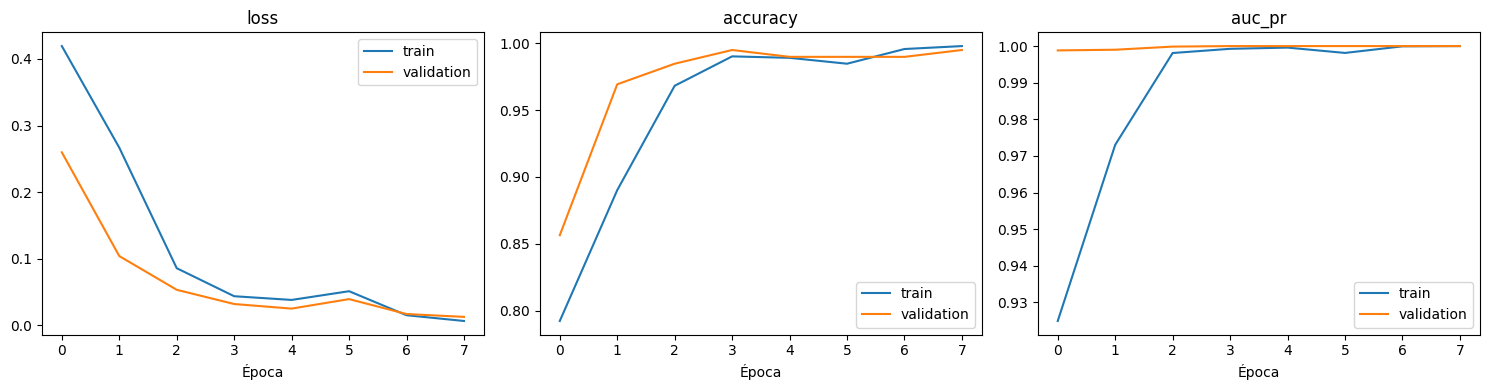

Modelo final (selección por validation): /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/experiments/mobilenetv2_af731904844ed80545ae
TEST: {'run_identity': 'af731904844ed80545ae9ae56b131fb4cf4c465acbeaf8af2620a4e36d46e07e', 'threshold_from_validation': 0.24371959269046783, 'accuracy': 0.9846153846153847, 'recall': 1.0, 'precision': 0.975, 'f1': 0.9873417721518988, 'average_precision': 0.9997833014424267, 'roc_auc': 0.9996712689020382, 'brier': 0.011269956635226732, 'confusion_matrix_0_ok_1_defect': [[75, 3], [0, 117]]}
DVC: registrando models/experiments/mobilenetv2_af731904844ed80545ae (límite 3600s; Drive puede tardar)...

To track the changes with git, run:

	git add models/experiments/.gitignore models/experiments/mobilenetv2_af731904844ed80545ae.dvc

To enable auto staging, run:

	dvc config core.autostage true

DVC: puntero actualizado models/experiments/mobilenetv2_af731904844ed80545ae.dvc
{'pointer': 'models/experiments/mobilenetv2_af731904844ed80545ae.dvc', 'update

In [ ]:
mobilenet_run = Path(EXISTING_MOBILENET_RUN) if EXISTING_MOBILENET_RUN else None
if STAGES["mobilenet"]:
    print("INICIANDO MobileNetV2: cuatro configuraciones de entrenamiento")
    mobilenet_run = run_hpo(CONFIG)
    print("MobileNetV2 seleccionado:", mobilenet_run)
    plot_history(mobilenet_run)

candidates = [p for p in (cnn_run, mobilenet_run) if p is not None]
if FINAL_MODEL == "cnn":
    selected_run = cnn_run
elif FINAL_MODEL == "mobilenet":
    selected_run = mobilenet_run
else:
    selected_run = select_model(CONFIG, candidates) if candidates else None
if selected_run is None:
    raise RuntimeError("No se produjo un modelo. Revisa las etapas de entrenamiento antes de continuar.")
print("Modelo final (selección por validation):", selected_run)

if STAGES["evaluate"]:
    if selected_run is None:
        raise ValueError("Selecciona una corrida antes de evaluar.")
    print("TEST:", evaluate(CONFIG, selected_run))
    print(version_with_dvc(CONFIG, selected_run, push=PUSH_DVC, remote=DVC_REMOTE))
if STAGES["dvc_models"]:
    for directory in ([mobilenet_run] if STAGES["mobilenet"] and mobilenet_run is not None and not (STAGES["evaluate"] and selected_run == mobilenet_run) else []):
        print(version_with_dvc(CONFIG, directory, push=PUSH_DVC, remote=DVC_REMOTE))
# Gráficos opcionales sin reentrenar: plot_history(selected_run)


## Exportando el modelo usando TensorFlow.js

In [6]:
selected_run = EXISTING_MOBILENET_RUN
print("Modelo a exportar:", selected_run / "best.keras")

Modelo a exportar: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/experiments/mobilenetv2_af731904844ed80545ae/best.keras


In [11]:
# Compatibilidad confinada al subproceso del conversor; no modifica NumPy del kernel.
TFJS_COMPAT_BOOTSTRAP = 'import sys, runpy\nimport numpy as np\nnp.__dict__.setdefault("object", object)\nnp.__dict__.setdefault("bool", bool)\nscript = sys.argv[1]\nsys.argv = sys.argv[1:]\nrunpy.run_path(script, run_name="__main__")\n'

def export_tfjs(config, directory, converter):
    """SavedModel -> graph_model; salida verificada y reutilizable, sin instalar paquetes."""
    directory = Path(directory)
    record = read_json(directory / "completed.json")
    check_artifacts(directory, record)
    manifest = load_manifest(config)
    if read_json(directory / "started.json")["manifest"] != manifest:
        raise ValueError(
            "El manifiesto actual no coincide con la corrida que se exportará."
        )
    converter = Path(converter).resolve()
    if not converter.is_file():
        raise FileNotFoundError(f"No existe el conversor: {converter}")
    identity = digest(
        {
            "run": record["identity"],
            "converter": file_hash(converter),
            "export_schema": 2,
        }
    )
    destination = config.root / "exports" / identity[:20]
    if (destination / "completed.json").is_file():
        completed = read_json(destination / "completed.json")
        check_artifacts(destination, completed)
        return destination
    pending = destination.with_name(destination.name + ".pending")
    if destination.exists():
        raise RuntimeError(f"Exportación final incompleta: revisa {destination}.")
    if pending.exists():
        archived = pending.with_name(pending.name + ".failed_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%f"))
        pending.rename(archived)
        print("Intento anterior conservado en:", archived)
    pending.mkdir(parents=True)
    model = tf.keras.models.load_model(directory / "best.keras")
    model.export(str(pending / "saved_model"))
    print("SavedModel guardado. Iniciando conversión TF.js...", flush=True)
    # Usar explícitamente el Python del entorno aislado.
    converter_python = converter.parent / "python"

    if not converter_python.is_file():
        raise FileNotFoundError(
            f"No existe el Python del conversor: {converter_python}"
        )

    print(
        "Python del conversor:",
        command(config, [str(converter_python), "--version"]).strip(),
    )

    command(
        config,
        [
            str(converter_python),
            str(converter),
            "--input_format=tf_saved_model",
            "--output_format=tfjs_graph_model",
            "--signature_name=serving_default",
            "--saved_model_tags=serve",
            str(pending / "saved_model"),
            str(pending / "web"),
        ],
        timeout=1800,
    )
    graph = read_json(pending / "web/model.json")
    if graph.get("format") != "graph-model":
        raise ValueError("El conversor no generó un graph-model válido.")
    for group in graph.get("weightsManifest", []):
        for name in group["paths"]:
            shard = (pending / "web" / name).resolve()
            if (
                not shard.is_relative_to((pending / "web").resolve())
                or not shard.is_file()
            ):
                raise ValueError(f"Shard inválido/ausente: {name}")
    threshold = read_json(directory / "validation.json")["threshold"]
    contract = {
        "labels": CLASSES,
        "positive_class": "def_front",
        "threshold": threshold,
        "input": "RGB float32 [0,1], resize bilinear 400x400, sin recorte",
        "output": "P(defecto)",
        "loader": "tf.loadGraphModel",
        "run_identity": record["identity"],
    }
    write_json(pending / "web/preprocessing.json", contract)
    # Referencia fija para comparar contra TF.js antes de desplegar.
    row = next(row for row in manifest["rows"] if row["split"] == "validation")
    tensor = next(
        iter(make_tf_dataset([config.root / row["path"]], [row["label"]], batch_size=1))
    )[0]
    np.save(pending / "web/reference_input.npy", tensor.numpy())
    write_json(
        pending / "web/reference_prediction.json",
        {
            "source": row["path"],
            "probability_python": float(model.predict(tensor, verbose=0).ravel()[0]),
            "equivalence_verified_in_browser": False,
        },
    )
    files = {
        p.relative_to(pending).as_posix(): file_hash(p)
        for p in pending.rglob("*")
        if p.is_file()
    }
    write_json(pending / "completed.json", {"identity": identity, "artifacts": files})
    pending.rename(destination)
    return destination


In [ ]:
# Preparar un conversor separado del entorno de entrenamiento.
# No reemplaza TensorFlow ni NumPy del kernel actual.

requirements = [
    "tensorflow==2.16.2",
    "tf-keras==2.16.0",
    "tensorflowjs==4.22.0",
    "tensorflow-hub==0.16.1",
    "tensorflow-decision-forests==1.9.2",
    "numpy==1.26.4",
    "jax==0.4.30",
    "jaxlib==0.4.30",
    "flax==0.8.5",
    "optax==0.2.3",
    "chex==0.1.87",
    "orbax-checkpoint==0.6.4",
    "setuptools<81",
]

spec = digest({"python": "3.11", "requirements": requirements})
environment = Path("/content") / f"rikuy_tfjs_{spec[:12]}"
converter_python = environment / "bin" / "python"
converter_path = environment / "bin" / "tensorflowjs_converter"
ready = environment / "ready.txt"

if not ready.is_file() or ready.read_text().strip() != spec:
    uv = shutil.which("uv")
    if uv is None:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "uv"],
            check=True,
            timeout=300,
        )
        uv = shutil.which("uv")

    if uv is None:
        raise FileNotFoundError("No se encontró uv después de instalarlo.")

    if not converter_python.is_file():
        subprocess.run(
            [uv, "venv", "--python", "3.11", str(environment)],
            check=True,
            timeout=600,
        )

    print("Preparando el entorno del conversor...")
    subprocess.run(
        [
            uv, "pip", "install",
            "--python", str(converter_python),
            *requirements,
        ],
        check=True,
        timeout=1800,
    )

    subprocess.run(
        [uv, "pip", "check", "--python", str(converter_python)],
        check=True,
        timeout=120,
    )

# Comprobar que el conversor puede arrancar antes de exportar.
verification = subprocess.run(
    [str(converter_path), "--help"],
    capture_output=True,
    text=True,
    timeout=120,
)
if verification.returncode:
    raise RuntimeError(verification.stderr or verification.stdout)

ready.write_text(spec, encoding="utf-8")
TFJS_CONVERTER = str(converter_path)

print("Conversor preparado:", TFJS_CONVERTER)
print("Modelo seleccionado:", selected_run / "best.keras")

Preparando el entorno del conversor...
Conversor preparado: /content/rikuy_tfjs_88f3b7e33684/bin/tensorflowjs_converter
Modelo seleccionado: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/experiments/mobilenetv2_af731904844ed80545ae/best.keras


In [12]:
export_dir = export_tfjs(CONFIG, selected_run, TFJS_CONVERTER)
print("Exportación:", export_dir)


Intento anterior conservado en: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/exports/9f8457f52f6310bc9b70.pending.failed_20261102T005159067899
Saved artifact at '/content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/exports/9f8457f52f6310bc9b70.pending/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 400, 400, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  133384080650128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133384038530320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133383928250832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133384038530128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133384038530896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133383928250448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133383928251792: TensorSpec(shape=(), dtype=tf.resource, name

In [14]:
print("RESUMEN DE EXPORTACIÓN", NOTEBOOK_VERSION)
print("Modelo elegido:", selected_run)
print("Validation:", read_json(selected_run / "validation.json"))

test_path = selected_run / "test.json"
if test_path.is_file():
    print("TEST:", read_json(test_path))

if export_dir is not None:
    export_dir = Path(export_dir)
    model_json = export_dir / "web" / "model.json"
    completed = export_dir / "completed.json"

    if not completed.is_file() or not model_json.is_file():
        raise RuntimeError(
            f"La exportación está incompleta: {export_dir}"
        )

    check_artifacts(export_dir, read_json(completed))
    print("Exportación completa y verificada:", export_dir)
    print("Modelo TensorFlow.js:", model_json)
else:
    print("La exportación todavía no terminó correctamente.")

RESUMEN DE EXPORTACIÓN RIKUY_COLAB_SOLO_EXPORTACION
Modelo elegido: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/experiments/mobilenetv2_af731904844ed80545ae
Validation: {'threshold': 0.24371959269046783, 'accuracy': 1.0, 'recall': 1.0, 'precision': 1.0, 'f1': 1.0, 'average_precision': 0.9999999999999999, 'roc_auc': 1.0, 'brier': 0.006161490687131598, 'confusion_matrix_0_ok_1_defect': [[78, 0], [0, 117]]}
TEST: {'run_identity': 'af731904844ed80545ae9ae56b131fb4cf4c465acbeaf8af2620a4e36d46e07e', 'threshold_from_validation': 0.24371959269046783, 'accuracy': 0.9846153846153847, 'recall': 1.0, 'precision': 0.975, 'f1': 0.9873417721518988, 'average_precision': 0.9997833014424267, 'roc_auc': 0.9996712689020382, 'brier': 0.011269956635226732, 'confusion_matrix_0_ok_1_defect': [[75, 3], [0, 117]]}
Exportación completa y verificada: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/exports/9f8457f52f6310bc9b70
Modelo TensorFlow.js: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEE

In [15]:
print(version_with_dvc(
    CONFIG,
    export_dir,
    push=PUSH_DVC,
    remote=DVC_REMOTE,
))

DVC: registrando exports/9f8457f52f6310bc9b70 (límite 3600s; Drive puede tardar)...

To track the changes with git, run:

	git add exports/.gitignore exports/9f8457f52f6310bc9b70.dvc

To enable auto staging, run:

	dvc config core.autostage true

DVC: puntero actualizado exports/9f8457f52f6310bc9b70.dvc
{'pointer': 'exports/9f8457f52f6310bc9b70.dvc', 'updated': True, 'push_requested': False}


In [16]:
print(command(
    CONFIG,
    ["dvc", "push", "exports/9f8457f52f6310bc9b70.dvc",
     "--remote", DVC_REMOTE],
    timeout=3600,
))

13 files pushed



## Testing

In [18]:
import functools
import http.server
import json
import shutil
import subprocess
import threading
from pathlib import Path

import numpy as np

WEB = Path(export_dir) / "web"
WORK = Path("/content/rikuy_equivalence")
WORK.mkdir(parents=True, exist_ok=True)

if not shutil.which("node") or not shutil.which("npm"):
    raise RuntimeError("Esta prueba necesita Node.js y npm en el entorno.")

# La referencia contiene exactamente el tensor usado en Python.
reference = read_json(WEB / "reference_prediction.json")
contract = read_json(WEB / "preprocessing.json")
image = np.load(WEB / "reference_input.npy", allow_pickle=False)

image.astype("<f4").tofile(WORK / "input.bin")
write_json(WORK / "reference.json", {
    "shape": list(image.shape),
    "probability_python": reference["probability_python"],
    "threshold": contract["threshold"],
})

# TensorFlow.js puro: no requiere GPU ni tfjs-node.
if not (WORK / "node_modules/@tensorflow/tfjs").is_dir():
    installation = subprocess.run(
        ["npm", "install", "--no-save", "--no-package-lock",
         "@tensorflow/tfjs@4.22.0"],
        cwd=WORK, capture_output=True, text=True, timeout=600,
    )
    if installation.returncode:
        raise RuntimeError(installation.stderr or installation.stdout)

javascript = r"""
const tf = require('@tensorflow/tfjs');
const fs = require('fs');

(async () => {
  await tf.setBackend('cpu');
  await tf.ready();

  const reference = JSON.parse(fs.readFileSync('reference.json', 'utf8'));
  const bytes = fs.readFileSync('input.bin');
  const buffer = bytes.buffer.slice(
    bytes.byteOffset, bytes.byteOffset + bytes.byteLength
  );
  const input = tf.tensor(
    new Float32Array(buffer), reference.shape, 'float32'
  );

  const model = await tf.loadGraphModel(process.argv[2]);
  const result = await model.executeAsync(input);
  const outputs = Array.isArray(result)
    ? result
    : typeof result.data === 'function'
      ? [result]
      : Object.values(result);

  if (outputs.length !== 1 || outputs[0].size !== 1) {
    throw new Error('Se esperaba una única probabilidad de defecto.');
  }

  const probability = (await outputs[0].data())[0];
  const difference = Math.abs(
    probability - reference.probability_python
  );
  const tolerance = 1e-4;
  const pythonDefect = reference.probability_python >= reference.threshold;
  const jsDefect = probability >= reference.threshold;

  const report = {
    probability_python: reference.probability_python,
    probability_tensorflowjs: probability,
    absolute_difference: difference,
    tolerance,
    threshold: reference.threshold,
    classification_python: pythonDefect ? 'DEFECTO' : 'OK',
    classification_tensorflowjs: jsDefect ? 'DEFECTO' : 'OK',
    passed: Number.isFinite(probability)
      && difference <= tolerance
      && pythonDefect === jsDefect
  };

  fs.writeFileSync('result.json', JSON.stringify(report, null, 2));
  console.log(JSON.stringify(report, null, 2));
  tf.dispose(result);
  input.dispose();
  model.dispose();

  if (!report.passed) process.exitCode = 1;
})().catch(error => {
  console.error(error);
  process.exitCode = 1;
});
"""
(WORK / "check.cjs").write_text(javascript, encoding="utf-8")

# Servidor accesible sólo dentro de esta máquina, para cargar model.json.
class QuietHandler(http.server.SimpleHTTPRequestHandler):
    def log_message(self, *args):
        pass

handler = functools.partial(QuietHandler, directory=str(WEB))
server = http.server.ThreadingHTTPServer(("127.0.0.1", 0), handler)
threading.Thread(target=server.serve_forever, daemon=True).start()

try:
    url = f"http://127.0.0.1:{server.server_port}/model.json"
    result = subprocess.run(
        ["node", "check.cjs", url],
        cwd=WORK, capture_output=True, text=True, timeout=600,
    )
    print(result.stdout)
    if result.returncode:
        raise RuntimeError(result.stderr or "La comparación no pasó.")
finally:
    server.shutdown()
    server.server_close()

{
  "probability_python": 0.00223900331184268,
  "probability_tensorflowjs": 0.0022390021476894617,
  "absolute_difference": 1.1641532182693481e-9,
  "tolerance": 0.0001,
  "threshold": 0.24371959269046783,
  "classification_python": "OK",
  "classification_tensorflowjs": "OK",
  "passed": true
}

